# 20.3 Context Vector

The key idea here is simple but **very important for understanding attention**:

> In attention-based Seq2Seq, the context vector is **not fixed**. It is recomputed at every decoding step based on what the decoder currently needs.

This is the main improvement over vanilla Seq2Seq.

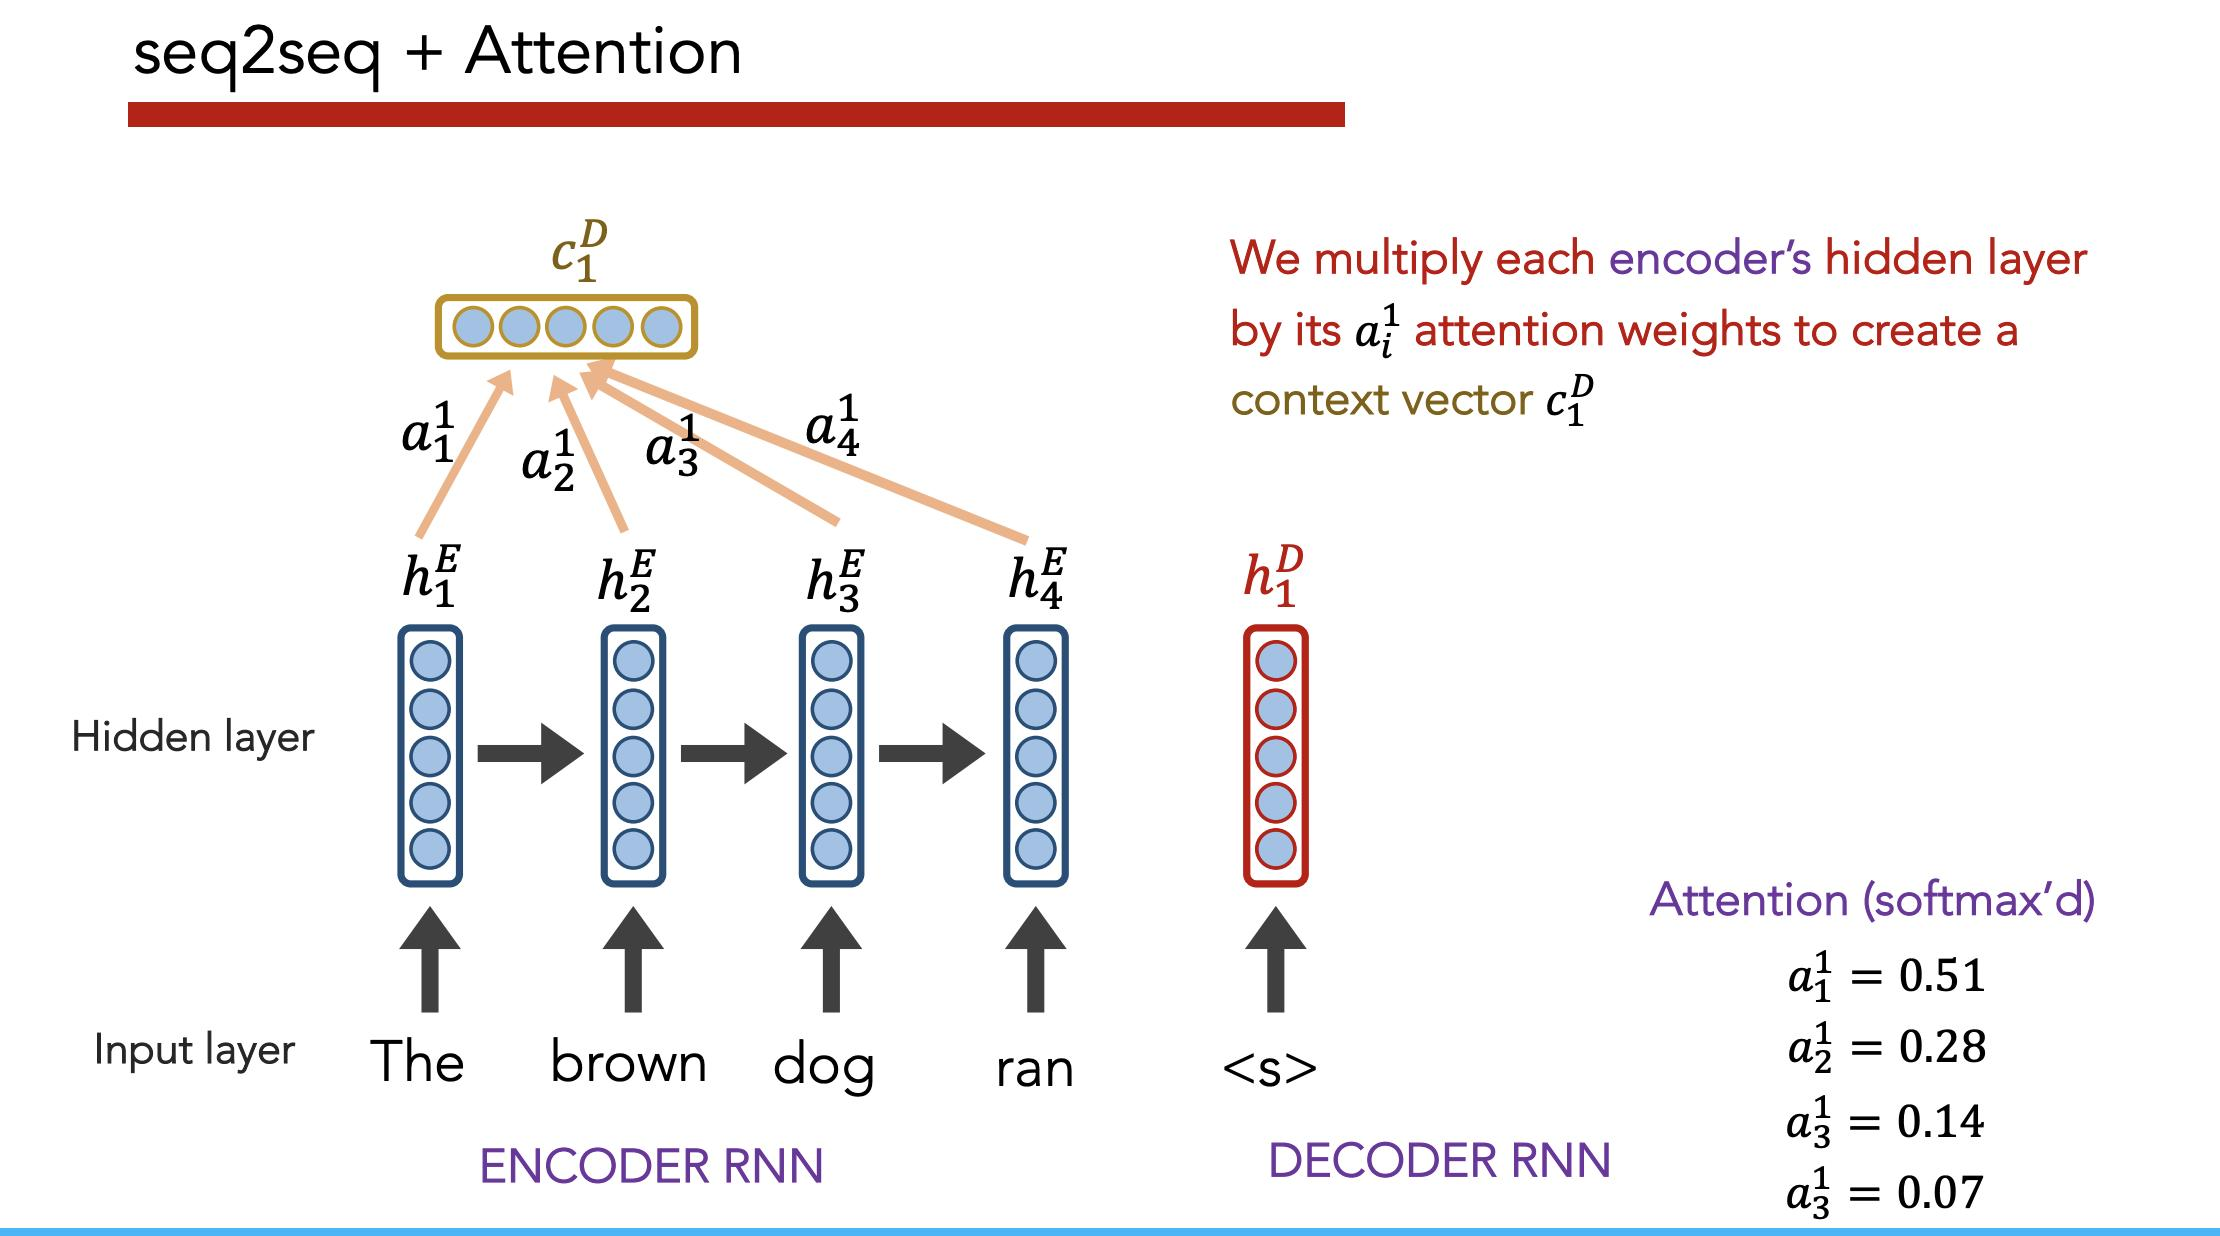

## 1. From One Context to Many Contexts

### Vanilla Seq2Seq

The encoder produces one final representation:

$$
\boxed{\mathbf{c}}
$$

and the decoder uses it throughout generation.
```text
Input
  ↓
Encoder
  ↓
c
  ↓
Decoder
  ↓
y₁ → y₂ → y₃ → ...
```

The same $c$ is effectively the decoder's compressed view of the input.

---

### Attention-Based Seq2Seq

The encoder instead produces:

$$
\mathbf{h}_1,\mathbf{h}_2,\ldots,\mathbf{h}_T
$$

Then, for every decoder timestep $t$, attention produces a new context:

$$
\boxed{\mathbf{c}_t}
$$

So:

$$
\mathbf{c}_1 \neq \mathbf{c}_2 \neq \mathbf{c}_3
$$

in general.
```text
Encoder
  │
  ├── h₁
  ├── h₂
  ├── h₃
  ├── h₄
  └── h₅
       │
       │
       ├── Attention at t=1 → c₁ → Decoder → y₁
       │
       ├── Attention at t=2 → c₂ → Decoder → y₂
       │
       └── Attention at t=3 → c₃ → Decoder → y₃
```

---

# 2. How Is $c_t$ Created?

At decoding step $t$, the decoder considers the encoder states:

$$
\mathbf{h}_1,\mathbf{h}_2,\ldots,\mathbf{h}_T
$$

and assigns an attention weight to each one:

$$
\alpha_{t,1},\alpha_{t,2},\ldots,\alpha_{t,T}
$$

The weights tell us:

> **How relevant is encoder position $i$ to the decoder at timestep $t$?**

The context vector is then:

$$
\boxed{
\mathbf{c}_t = \sum_{i=1}^{T} \alpha_{t,i}\mathbf{h}_i
}
$$

This is a **weighted sum of encoder hidden states**.

---

# 3. Simple Example

Suppose the input is:

> **"The cat eats fish"**

The encoder produces:

$$
h_1,h_2,h_3,h_4
$$

corresponding roughly to:
```text
h₁       h₂       h₃       h₄
The      cat      eats     fish
```

### Decoder step 1

Suppose the decoder needs information about **cat**:

$$
\alpha_1 = [0.05,\;0.80,\;0.10,\;0.05]
$$

Then:

$$
c_1 = 0.05h_1 + 0.80h_2 + 0.10h_3 + 0.05h_4
$$

So $c_1$ is strongly influenced by $h_2$.

---

### Decoder step 2

Now the decoder needs information about **eats**:

$$
\alpha_2 = [0.05,\;0.10,\;0.80,\;0.05]
$$

Therefore:

$$
c_2 = 0.05h_1 + 0.10h_2 + 0.80h_3 + 0.05h_4
$$

Now $c_2$ is strongly influenced by $h_3$.

---

### Decoder step 3

Suppose it needs **fish**:

$$
\alpha_3 = [0.05,\;0.05,\;0.10,\;0.80]
$$

Then:

$$
c_3 = 0.05h_1 + 0.05h_2 + 0.10h_3 + 0.80h_4
$$

Now $c_3$ focuses strongly on $h_4$.

---

# 4. Visualizing the Change
```text
Input:     The       cat       eats       fish
            │         │         │          │
           h₁        h₂        h₃         h₄

             Decoder timestep 1
                    ↓
           [0.05, 0.80, 0.10, 0.05]
                    ↓
                   c₁
                    ↓
                   y₁


             Decoder timestep 2
                    ↓
           [0.05, 0.10, 0.80, 0.05]
                    ↓
                   c₂
                    ↓
                   y₂


             Decoder timestep 3
                    ↓
           [0.05, 0.05, 0.10, 0.80]
                    ↓
                   c₃
                    ↓
                   y₃
```

The **encoder states stay available**, but the **attention distribution changes**.

Therefore the context changes.

---

# 5. The Most Important Distinction

Don't confuse these three things:

| Concept             | Meaning                                                    |
| ------------------- | ---------------------------------------------------------- |
| $h_i$               | Encoder representation at input position $i$              |
| $\alpha_{t,i}$      | Attention weight for input $i$ at decoder step $t$         |
| $c_t$               | Context vector constructed for decoder step $t$            |

The relationship is:

$$
\boxed{
\text{Encoder states}
\overset{\text{attention weights}}{\longrightarrow}
\text{Context vector}
}
$$

More explicitly:

$$
\boxed{
\mathbf{c}_t = \sum_i \alpha_{t,i}\mathbf{h}_i
}
$$

---

# 6. Why This Solves the Bottleneck

Vanilla Seq2Seq:

$$
x_1,\ldots,x_T \rightarrow \boxed{c} \rightarrow \text{decoder}
$$

Attention:

$$
x_1,\ldots,x_T \rightarrow \boxed{h_1,\ldots,h_T}
$$

and then at each timestep:

$$
\boxed{
h_1,\ldots,h_T \rightarrow c_t \rightarrow \text{decoder}
}
$$

So the decoder no longer has to depend entirely on a single fixed representation.

It can effectively say:

> **"For this output token, I need this part of the input."**

Then at the next timestep:

> **"Now I need a different part."**

That's the intuition behind a **dynamic context vector**.

---

## 🔗 Connection to What Comes Next

You already know self-attention conceptually from your DL work. Here we're building toward the more formal attention computation:

$$
\text{Decoder state}
\rightarrow
\text{attention scores}
\rightarrow
\text{softmax weights}
\rightarrow
\text{weighted encoder states}
\rightarrow
\mathbf{c}_t
$$

Later, this maps naturally onto the **Query–Key–Value** formulation.

### Must Know

$$
\boxed{
\mathbf{c}_t = \sum_{i=1}^{T} \alpha_{t,i}\mathbf{h}_i
}
$$

The crucial word is **$t$**.

Because $t$ changes:

$$
\boxed{
\mathbf{c}_1,\mathbf{c}_2,\mathbf{c}_3,\ldots
}
$$

can all be different.

### What you should remember

1. Vanilla Seq2Seq uses a **fixed context vector**.
2. Attention creates a **new context vector at every decoder timestep**.
3. $c_t$ is a weighted combination of encoder hidden states.
4. Attention weights determine which input information matters **right now**.
5. Changing attention weights → changing context vector.
6. This dynamic context is what removes much of the fixed-vector information bottleneck.

---